# Hardware-Efficient Ansatz (HEA) — Qiskit

**Chapter / concept:** Variational Ansatz — Hardware-Efficient Ansatz (HEA)

**Circuit:** 2-qubit HEA, `REPS = 2` entangling layers (so 3 rotation blocks total).
Each rotation block applies `RY(theta)` then `RZ(theta)` on every qubit; each entangling
layer applies a single linear-chain `CX(control=0, target=1)`. Structure:

```
[R0] - CX - [R1] - CX - [R2]
```

where each `[Rb]` = `RY,RZ` on qubit 0 **and** `RY,RZ` on qubit 1 (order: RY then RZ, per qubit).

**Global SETUP (identical in both notebooks — do not diverge):**
- `N_QUBITS = 2`
- `REPS = 2` (→ 3 rotation blocks, 2 CX entanglers)
- Gate sequence: for `b in 0..REPS`: `RY(theta[b,0,0])` on q0, `RZ(theta[b,0,1])` on q0,
  `RY(theta[b,1,0])` on q1, `RZ(theta[b,1,1])` on q1; then if `b < REPS`: `CX(0,1)`
- `THETA` is a **fixed, hard-coded** 12-angle array (no training/optimization loop —
  this is a structural/numerical matching check of the ansatz itself, not a VQE run)
- `SHOTS = 10000`, `SEED = 42`
- **QUBIT ORDERING CONTRACT:** qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention). CUDA-Q's native convention is the opposite
  (qubit 0 = leftmost/MSB) and is corrected explicitly in the CUDA-Q notebook.
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order, is rotated to be real and positive.
- **Basis ordering for matrices/vectors:** `{|00>, |01>, |10>, |11>}` ascending binary order.

**Independently hand/NumPy-verified target result** (see final `_RESULT` cell) —
probabilities keyed by bitstring, qubit0 = rightmost bit:

```
{'00': 0.6295, '01': 0.1862, '10': 0.0209, '11': 0.1634}
```

> ⚠️ **Run all cells top to bottom.** Note on the diff-check: identical `SEED` values passed to Qiskit's Aer and to CUDA-Q do **not** synchronize their PRNGs (different simulator engines, different RNG algorithms) — shot-sampled counts from the two notebooks will be statistically close but not bit-identical. The exact cross-check is done on the **noise-free statevector probabilities**, not the sampled counts.


In [1]:
# Install Qiskit + Aer simulator + pylatexenc.
# Exact PyPI package names: qiskit, qiskit-aer, pylatexenc
# pylatexenc is required by circuit.draw(output="mpl") for gate-label rendering.
# Tested-against API: Qiskit >= 1.0 (Aer lives in the separate `qiskit-aer` package,
# NOT qiskit.providers.aer, which is deprecated/removed in modern releases).
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

# ---- Global SETUP (must match the CUDA-Q notebook exactly) ----
N_QUBITS = 2
REPS = 2                       # number of entangling layers -> REPS+1 rotation blocks
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "hea_ansatz"

# THETA[block, qubit, gate]; gate index 0 = RY angle, gate index 1 = RZ angle
THETA = np.array([
    [[0.31, 0.52], [0.18, 0.64]],   # block 0: qubit0 -> (RY, RZ), qubit1 -> (RY, RZ)
    [[0.77, 0.09], [0.41, 0.23]],   # block 1
    [[0.58, 0.36], [0.12, 0.69]],   # block 2
])
assert THETA.shape == (REPS + 1, N_QUBITS, 2)

print("N_QUBITS =", N_QUBITS)
print("REPS     =", REPS)
print("SHOTS    =", SHOTS)
print("SEED     =", SEED)
print("THETA =\n", THETA)


N_QUBITS = 2
REPS     = 2
SHOTS    = 10000
SEED     = 42
THETA =
 [[[0.31 0.52]
  [0.18 0.64]]

 [[0.77 0.09]
  [0.41 0.23]]

 [[0.58 0.36]
  [0.12 0.69]]]


In [3]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="HEA")

for b in range(REPS + 1):
    for q in range(N_QUBITS):
        ry_ang, rz_ang = THETA[b, q, 0], THETA[b, q, 1]
        qc.ry(ry_ang, q)   # RY: sets the |0>/|1> population mix on qubit q
        qc.rz(rz_ang, q)   # RZ: adds a relative phase on qubit q (no population change)
    if b < REPS:
        qc.cx(0, 1)        # entangling layer: linear-chain CNOT, control=q0, target=q1
    qc.barrier()           # visual separator only — identity on the statevector

print(qc)


     ┌──────────┐┌──────────┐      ░ ┌──────────┐┌──────────┐      ░ »
q_0: ┤ Ry(0.31) ├┤ Rz(0.52) ├──■───░─┤ Ry(0.77) ├┤ Rz(0.09) ├──■───░─»
     ├──────────┤├──────────┤┌─┴─┐ ░ ├──────────┤├──────────┤┌─┴─┐ ░ »
q_1: ┤ Ry(0.18) ├┤ Rz(0.64) ├┤ X ├─░─┤ Ry(0.41) ├┤ Rz(0.23) ├┤ X ├─░─»
     └──────────┘└──────────┘└───┘ ░ └──────────┘└──────────┘└───┘ ░ »
c: 2/════════════════════════════════════════════════════════════════»
                                                                     »
«     ┌──────────┐┌──────────┐ ░ 
«q_0: ┤ Ry(0.58) ├┤ Rz(0.36) ├─░─
«     ├──────────┤├──────────┤ ░ 
«q_1: ┤ Ry(0.12) ├┤ Rz(0.69) ├─░─
«     └──────────┘└──────────┘ ░ 
«c: 2/═══════════════════════════
«                                


/usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/matplotlib.py:273: UserWarning: Style JSON file 'default.json' not found in any of these locations: /usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/styles/default.json, default.json. Will use default style.
  self._style, def_font_ratio = load_style(


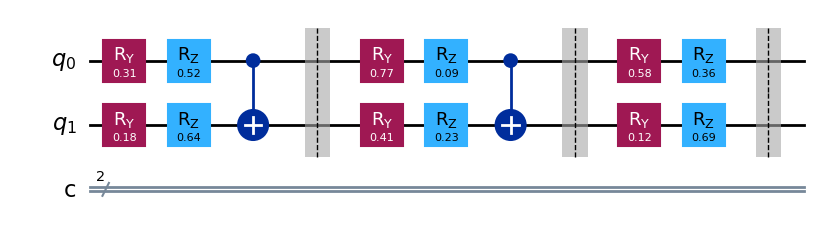

In [4]:
fig = qc.draw(output="mpl", style={"name": "default"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
def RY_matrix(theta):
    c, s = np.cos(theta / 2), np.sin(theta / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ_matrix(theta):
    return np.array([[np.exp(-1j * theta / 2), 0], [0, np.exp(1j * theta / 2)]], dtype=complex)

print("Basis ordering for all matrices below: {|00>, |01>, |10>, |11>} (qubit0 = rightmost/LSB)\n")
print("Example RY(THETA[0,0,0]) matrix:\n", np.round(RY_matrix(THETA[0, 0, 0]), 4))
print("\nExample RZ(THETA[0,0,1]) matrix:\n", np.round(RZ_matrix(THETA[0, 0, 1]), 4))

# (a) Hand-built full 4x4 unitary in NumPy, Qiskit's tensor convention (qubit0 = LSB,
#     i.e. rightmost tensor factor: full_op = kron(gate_on_q1, gate_on_q0))
I2 = np.eye(2, dtype=complex)

def single_qubit_op(gate, q, n=N_QUBITS):
    mats = [gate if qi == q else I2 for qi in range(n - 1, -1, -1)]
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def cx01_op(n=N_QUBITS):
    P0 = np.array([[1, 0], [0, 0]], dtype=complex)
    P1 = np.array([[0, 0], [0, 1]], dtype=complex)
    X  = np.array([[0, 1], [1, 0]], dtype=complex)
    def term(proj, apply_x):
        mats = []
        for qi in range(n - 1, -1, -1):
            if qi == 0:
                mats.append(proj)
            elif qi == 1 and apply_x:
                mats.append(X)
            else:
                mats.append(I2)
        out = mats[0]
        for m in mats[1:]:
            out = np.kron(out, m)
        return out
    return term(P0, False) + term(P1, True)

CX01 = cx01_op()
U_hand = np.eye(2 ** N_QUBITS, dtype=complex)
for b in range(REPS + 1):
    for q in range(N_QUBITS):
        U_hand = single_qubit_op(RY_matrix(THETA[b, q, 0]), q) @ U_hand   # RY applied first...
        U_hand = single_qubit_op(RZ_matrix(THETA[b, q, 1]), q) @ U_hand   # ...then RZ (matches circuit order)
    if b < REPS:
        U_hand = CX01 @ U_hand

# (b) Framework's own operator extraction (barriers are no-ops for Operator())
U_qiskit = Operator(qc).data

print("\nHand-built operator U (rounded, 4 dp):\n", np.round(U_hand, 4))
print("\nQiskit Operator(qc) (rounded, 4 dp):\n", np.round(U_qiskit, 4))

max_diff = np.max(np.abs(U_hand - U_qiskit))
print("\nMax |difference| between hand-built and Qiskit operator:", max_diff)
assert max_diff < 1e-8, "Mismatch between hand-built and Qiskit operator!"
print("Cross-check PASSED: hand-built matrix matches Qiskit's Operator() exactly.")


Basis ordering for all matrices below: {|00>, |01>, |10>, |11>} (qubit0 = rightmost/LSB)

Example RY(THETA[0,0,0]) matrix:
 [[ 0.988 +0.j -0.1544+0.j]
 [ 0.1544+0.j  0.988 +0.j]]

Example RZ(THETA[0,0,1]) matrix:
 [[0.9664-0.2571j 0.    +0.j    ]
 [0.    +0.j     0.9664+0.2571j]]

Hand-built operator U (rounded, 4 dp):
 [[ 0.1843-0.7717j -0.2313+0.1721j -0.3693+0.2302j -0.3127-0.0145j]
 [ 0.3651-0.2299j  0.8533-0.0284j  0.253 +0.0622j -0.1197+0.0516j]
 [ 0.1414-0.03j   -0.3524-0.0803j  0.7738+0.2178j -0.3675-0.2594j]
 [ 0.4026-0.0372j -0.2384-0.0204j  0.1841+0.2504j  0.4284+0.7065j]]

Qiskit Operator(qc) (rounded, 4 dp):
 [[ 0.1843-0.7717j -0.2313+0.1721j -0.3693+0.2302j -0.3127-0.0145j]
 [ 0.3651-0.2299j  0.8533-0.0284j  0.253 +0.0622j -0.1197+0.0516j]
 [ 0.1414-0.03j   -0.3524-0.0803j  0.7738+0.2178j -0.3675-0.2594j]
 [ 0.4026-0.0372j -0.2384-0.0204j  0.1841+0.2504j  0.4284+0.7065j]]

Max |difference| between hand-built and Qiskit operator: 2.482534153247273e-16
Cross-check PASSED: h

In [6]:
sv = Statevector(qc)   # exact statevector; qiskit qubit0 = LSB already, no reversal needed
amps = sv.data

# Global phase normalization: first amplitude with |amp| > 1e-9 in ascending bitstring
# order is rotated to be real and positive.
phase = None
for i in range(2 ** N_QUBITS):
    if abs(amps[i]) > 1e-9:
        phase = np.angle(amps[i])
        break
amps_norm = amps * np.exp(-1j * phase)

print("Bitstring convention: qubit0 = rightmost character\n")
for i in range(2 ** N_QUBITS):
    bitstring = format(i, f"0{N_QUBITS}b")
    print(f"  |{bitstring}>: raw={amps[i]:.6f}   normalized={amps_norm[i]:.6f}")

probs_sv = {format(i, f"0{N_QUBITS}b"): float(abs(amps_norm[i]) ** 2) for i in range(2 ** N_QUBITS)}
print("\nStatevector-derived probabilities (sorted by bitstring):")
for k in sorted(probs_sv):
    print(f"  {k}: {probs_sv[k]:.6f}")
print("\nPhase removed (rad):", phase)


Bitstring convention: qubit0 = rightmost character

  |00>: raw=0.184337-0.771716j   normalized=0.793426+0.000000j
  |01>: raw=0.365104-0.229902j   normalized=0.308436+0.301701j
  |10>: raw=0.141350-0.030020j   normalized=0.062038+0.130508j
  |11>: raw=0.402559-0.037206j   normalized=0.129715+0.382899j

Statevector-derived probabilities (sorted by bitstring):
  00: 0.629525
  01: 0.186156
  10: 0.020881
  11: 0.163438

Phase removed (rad): -1.3363235535455054


**Ordering-fix note:** no bit reversal was applied in this notebook. Qiskit already
indexes `Statevector` amplitudes and measurement `counts` with qubit 0 as the
least-significant (rightmost) bit, which is exactly the SETUP contract, so the raw
output is used as-is. Only the global-phase normalization (rotate the first nonzero
ascending-order amplitude to real-positive) was applied.

In [7]:
qc_meas = qc.copy()
qc_meas.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
tqc = transpile(qc_meas, sim, seed_transpiler=SEED)
result = sim.run(tqc, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

# Qiskit counts keys are already "q1 q0" bitstrings (qubit0 rightmost) -> no reordering needed
probs_counts = {k: v / SHOTS for k, v in counts.items()}
for i in range(2 ** N_QUBITS):
    k = format(i, f"0{N_QUBITS}b")
    probs_counts.setdefault(k, 0.0)

print("Measured counts:", counts)
print("\nMeasured probabilities (sorted by bitstring):")
for k in sorted(probs_counts):
    print(f"  {k}: {probs_counts[k]:.4f}")


Measured counts: {'11': 1615, '01': 1937, '10': 207, '00': 6241}

Measured probabilities (sorted by bitstring):
  00: 0.6241
  01: 0.1937
  10: 0.0207
  11: 0.1615


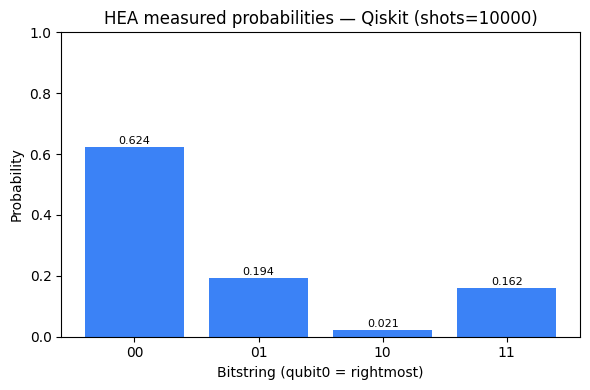

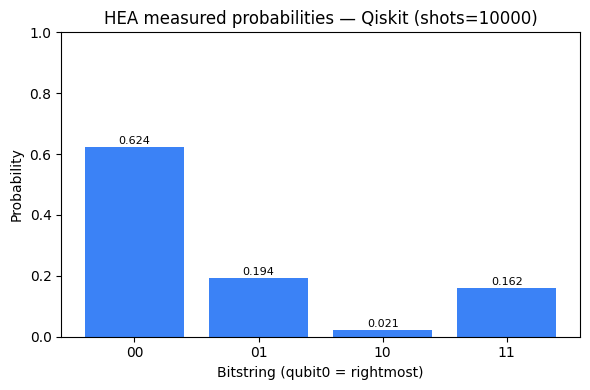

In [8]:
fig2, ax = plt.subplots(figsize=(6, 4))
labels = sorted(probs_counts.keys())
values = [probs_counts[k] for k in labels]
ax.bar(labels, values, color="#3b82f6")
ax.set_ylim(0, 1)
ax.set_xlabel("Bitstring (qubit0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title(f"HEA measured probabilities — Qiskit (shots={SHOTS})")
for i, v in enumerate(values):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
fig2.tight_layout()
fig2.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
depth = qc_meas.depth()
op_counts = qc_meas.count_ops()
print("Circuit depth:", depth)
print("Gate counts:", dict(op_counts))


Circuit depth: 9
Gate counts: {'ry': 6, 'rz': 6, 'barrier': 3, 'cx': 2, 'measure': 2}


In [10]:
print("Convention notes:")
print("- Qiskit qubit 0 = LSB = rightmost character in every printed bitstring; no bit reversal applied.")
print(f"- Global phase normalized so the first nonzero ascending-order amplitude is real positive;"
      f" phase removed = {phase:.6f} rad.")
print("- Basis ordering for all matrices/vectors: ascending binary index {|00>,|01>,|10>,|11>}.")


Convention notes:
- Qiskit qubit 0 = LSB = rightmost character in every printed bitstring; no bit reversal applied.
- Global phase normalized so the first nonzero ascending-order amplitude is real positive; phase removed = -1.336324 rad.
- Basis ordering for all matrices/vectors: ascending binary index {|00>,|01>,|10>,|11>}.


In [11]:
QISKIT_RESULT = {k: probs_sv[k] for k in sorted(probs_sv)}
print("QISKIT_RESULT =", QISKIT_RESULT)


QISKIT_RESULT = {'00': 0.6295252214311048, '01': 0.18615594251278722, '10': 0.020881026340260546, '11': 0.16343780971584781}


In [12]:
# ---- Cross-notebook diff check ----
# Paste the CUDAQ_RESULT dict printed at the end of the CUDA-Q notebook, then uncomment:
#
# CUDAQ_RESULT = {"00": ..., "01": ..., "10": ..., "11": ...}
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print("Max probability delta:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results do not match!"
#
# Independently re-derived (NumPy, from scratch) expected result, qubit0 = rightmost bit:
# {"00": 0.629525, "01": 0.186156, "10": 0.020881, "11": 0.163438}
# QISKIT_RESULT above must match this to numerical precision (it is the exact statevector,
# not shot-sampled, so agreement should be to ~1e-8, not just 1e-3).
